Loading committed 2023 data (PV + demand)...


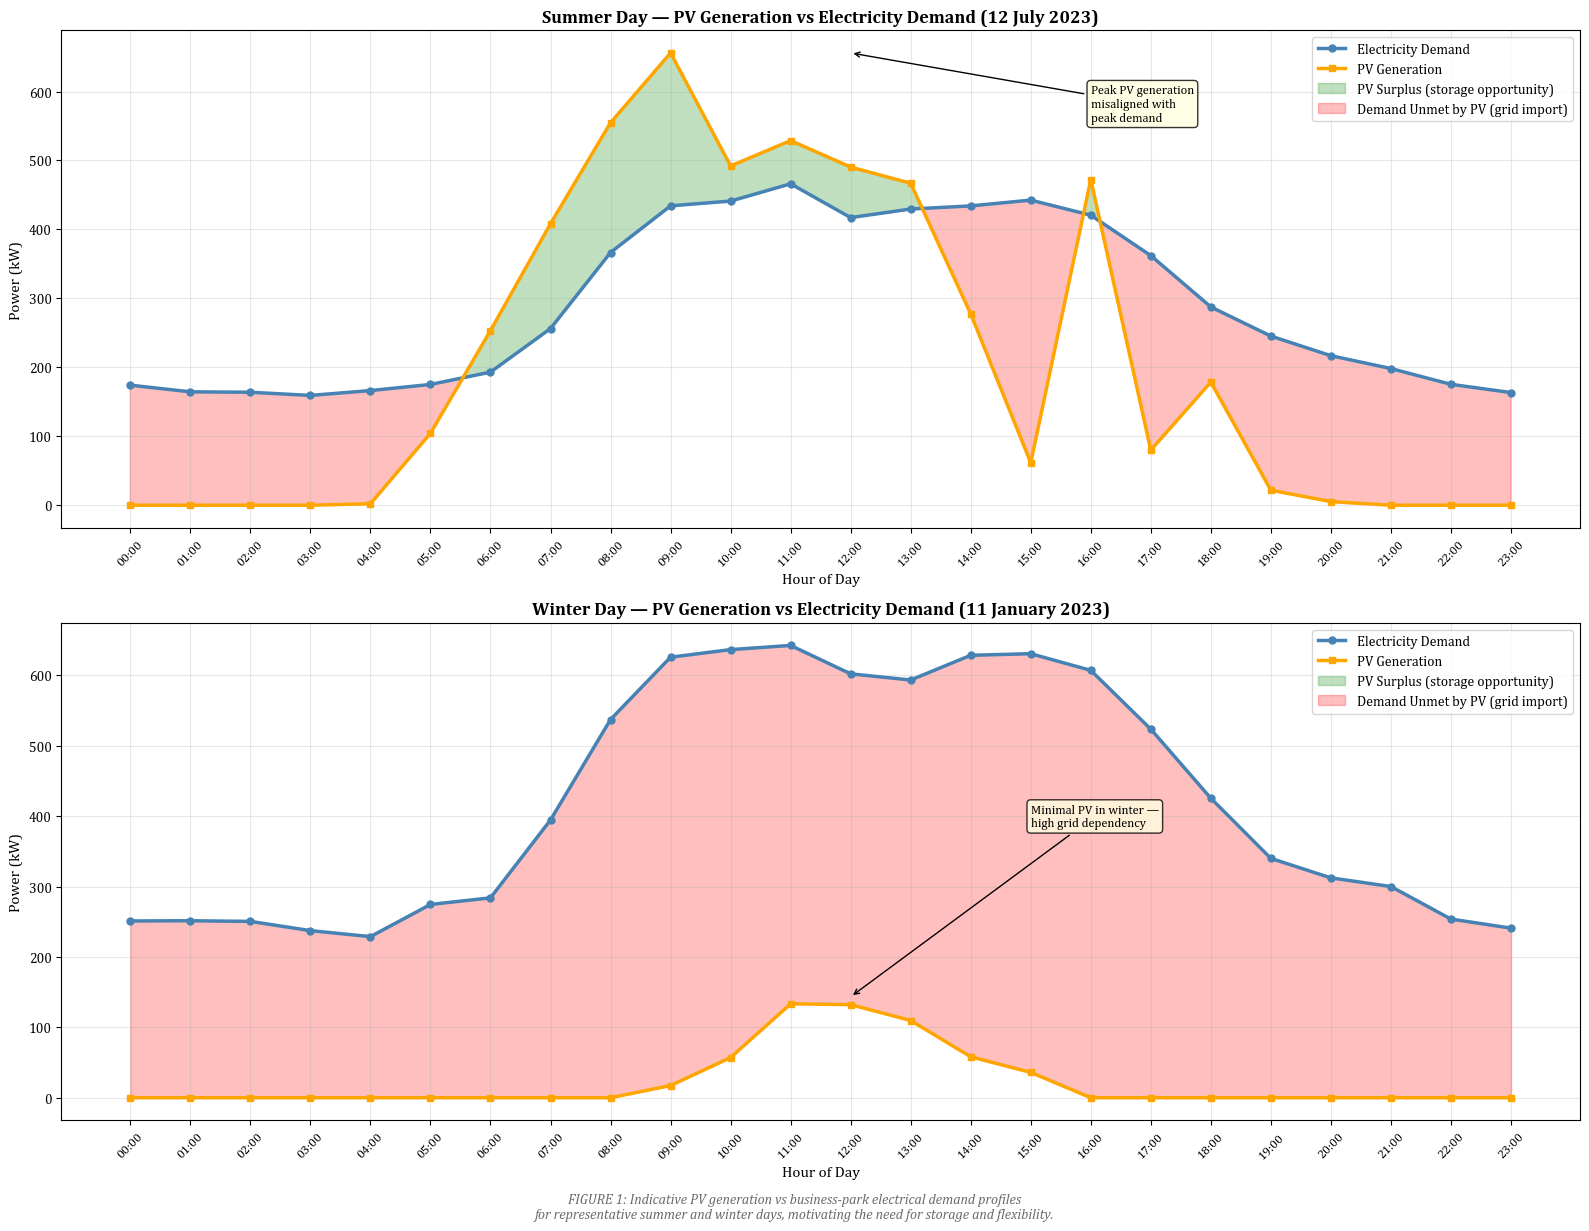

Stage 4 complete — Figure 1 saved!


In [1]:
import os
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import pvlib
import logging
import warnings

logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

import platform
if platform.system() == 'Windows':
    base = r"C:\Users\sosoq\Documents\GitHub\EdenCampus-PhD\EdenCampus_PhD"
else:
    base = os.path.expanduser("~/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD")
for folder in ["01_data/weather", "01_data/demand",
               "04_results/figures", "04_results/tables"]:
    os.makedirs(os.path.join(base, folder), exist_ok=True)
latitude  = 56.3398
longitude = -2.7967

print("Loading committed 2023 data (PV + demand)...")
from data_prep import load_pv_profile_for_year, load_inputs
# PV output in kW from committed weather CSV (1 MW system)
system_capacity_kW = 1000
pv_pu_full = load_pv_profile_for_year(base, 2023)
pv_output = (pv_pu_full * system_capacity_kW)
hours_ts = pv_output.index
# Electrical demand (kW) from committed authoritative CSV
demand_series = load_inputs(base, representative_weeks=False, verbose=False)["elec_demand"]
demand_series = demand_series.reindex(hours_ts).ffill().bfill()
demand_series.name = "demand_kW"

summer_date   = '2023-07-12'
winter_date   = '2023-01-11'
summer_pv     = pv_output[summer_date].values
winter_pv     = pv_output[winter_date].values
summer_demand = demand_series[summer_date].values
winter_demand = demand_series[winter_date].values
hour_labels   = [f'{h:02d}:00' for h in range(24)]

fig, axes = plt.subplots(2, 1, figsize=(16, 12))

axes[0].plot(range(24), summer_demand, color='steelblue', linewidth=2.5,
             marker='o', markersize=5, label='Electricity Demand', zorder=3)
axes[0].plot(range(24), summer_pv, color='orange', linewidth=2.5,
             marker='s', markersize=5, label='PV Generation', zorder=3)
axes[0].fill_between(range(24), summer_demand, summer_pv,
                     where=(summer_pv > summer_demand), interpolate=True,
                     alpha=0.25, color='green', label='PV Surplus (storage opportunity)')
axes[0].fill_between(range(24), summer_demand, summer_pv,
                     where=(summer_pv < summer_demand), interpolate=True,
                     alpha=0.25, color='red', label='Demand Unmet by PV (grid import)')
axes[0].set_title('Summer Day — PV Generation vs Electricity Demand (12 July 2023)',
                   fontsize=13, fontweight='bold')
axes[0].set_ylabel('Power (kW)', fontsize=11)
axes[0].set_xlabel('Hour of Day', fontsize=11)
axes[0].set_xticks(range(24))
axes[0].set_xticklabels(hour_labels, rotation=45, fontsize=9)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].annotate('Peak PV generation\nmisaligned with\npeak demand',
                  xy=(12, max(summer_pv)),
                  xytext=(16, max(summer_pv) * 0.85),
                  arrowprops=dict(arrowstyle='->', color='black'),
                  fontsize=9,
                  bbox=dict(boxstyle='round,pad=0.3',
                            facecolor='lightyellow', alpha=0.8))

axes[1].plot(range(24), winter_demand, color='steelblue', linewidth=2.5,
             marker='o', markersize=5, label='Electricity Demand', zorder=3)
axes[1].plot(range(24), winter_pv, color='orange', linewidth=2.5,
             marker='s', markersize=5, label='PV Generation', zorder=3)
axes[1].fill_between(range(24), winter_demand, winter_pv,
                     where=(winter_pv > winter_demand), interpolate=True,
                     alpha=0.25, color='green', label='PV Surplus (storage opportunity)')
axes[1].fill_between(range(24), winter_demand, winter_pv,
                     where=(winter_pv < winter_demand), interpolate=True,
                     alpha=0.25, color='red', label='Demand Unmet by PV (grid import)')
axes[1].set_title('Winter Day — PV Generation vs Electricity Demand (11 January 2023)',
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('Power (kW)', fontsize=11)
axes[1].set_xlabel('Hour of Day', fontsize=11)
axes[1].set_xticks(range(24))
axes[1].set_xticklabels(hour_labels, rotation=45, fontsize=9)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)
axes[1].annotate('Minimal PV in winter —\nhigh grid dependency',
                  xy=(12, max(winter_pv) + 10),
                  xytext=(15, max(winter_demand) * 0.6),
                  arrowprops=dict(arrowstyle='->', color='black'),
                  fontsize=9,
                  bbox=dict(boxstyle='round,pad=0.3',
                            facecolor='lightyellow', alpha=0.8))

fig.text(0.5, -0.02,
         'FIGURE 1: Indicative PV generation vs business-park electrical demand profiles\n'
         'for representative summer and winter days, motivating the need for storage and flexibility.',
         ha='center', fontsize=10, style='italic', color='dimgray')

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures", "figure1_pv_vs_demand.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()
print("Stage 4 complete — Figure 1 saved!")